## Упражнения

Загрузите следующие два временных ряда.

In [1]:
import sys

if 'google.colab' in sys.modules:
    !pip install -U -qq tsa-course

In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import requests
from io import BytesIO
from tsa_course.lecture2 import run_sequence_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.api import SimpleExpSmoothing
np.random.seed(0) # reproducibility

In [3]:
# метод вывода разложения ряда на компоненты
def seas_decomp_plots(original, decomposition):
    _, axes = plt.subplots(3, 1, sharex=True, sharey=False, figsize=(7, 5))
    axes[0].plot(original, label='Original')
    axes[0].legend(loc='upper left')
    axes[1].plot(decomposition.trend, label='Trend')
    axes[1].legend(loc='upper left')
    axes[2].plot(decomposition.seasonal, label='Seasonality')
    axes[2].legend(loc='upper left')
    plt.show()

In [4]:
# метод вывода графиков
def run_sequence_plot(x, y, title, xlabel="Time", ylabel="Values", ax=None):
    if ax is None:
        _, ax = plt.subplots(1,1, figsize=(10, 3.5))
    ax.plot(x, y, 'k-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax

In [5]:
def mse(observations, estimates):
    """
    INPUT:
        observations - numpy array of values indicating observed values
        estimates - numpy array of values indicating an estimate of values
    OUTPUT:
        Mean Square Error value
    """
    # check arg types
    assert type(observations) == type(np.array([])), "'observations' must be a numpy array"
    assert type(estimates) == type(np.array([])), "'estimates' must be a numpy array"
    # check length of arrays equal
    assert len(observations) == len(estimates), "Arrays must be of equal length"

    # calculations
    difference = observations - estimates
    sq_diff = difference ** 2
    mse = np.mean(sq_diff)

    return mse

In [6]:
# загрузка 1-ого датасета
response = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts1.npy?download=1")
response.raise_for_status()
smoothing_ts1 = np.load(BytesIO(response.content))
print(len(smoothing_ts1))

# загрузка 2-ого датасета
response = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts4_4.npy?download=1")
response.raise_for_status()
smoothing_ts2 = np.load(BytesIO(response.content))
print(len(smoothing_ts2))

144
1000


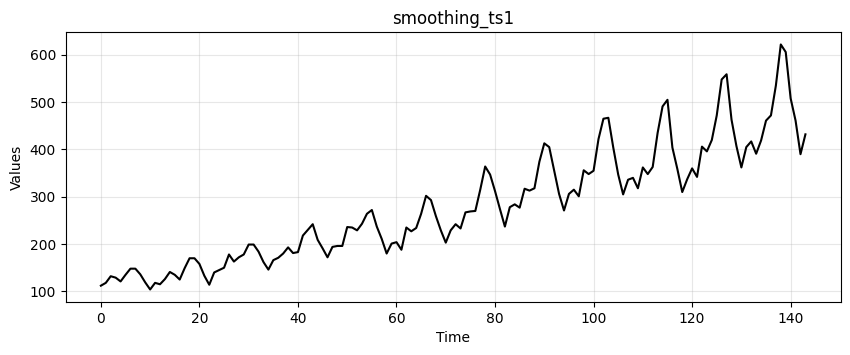

In [7]:
run_sequence_plot(np.arange(len(smoothing_ts1)), smoothing_ts1, title="smoothing_ts1");

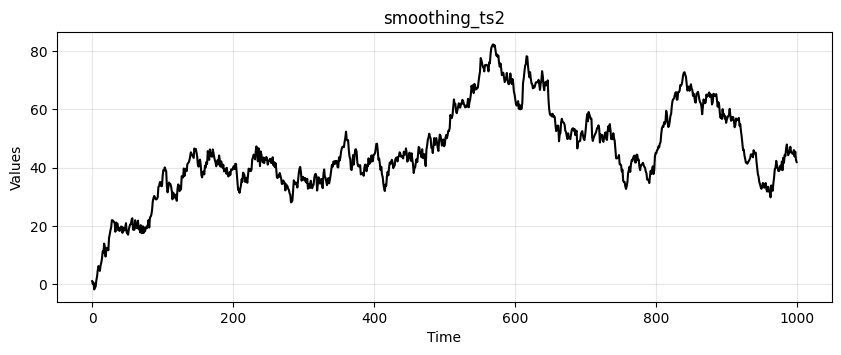

In [8]:
run_sequence_plot(np.arange(len(smoothing_ts2)), smoothing_ts2, title="smoothing_ts2");

Используя то, что вы узнали в этой и предыдущих лекциях, выполните следующие действия.

1. Создайте две временные переменные с именами `mytime1` и `mytime2`, которые начинаются с 0 и имеют такую ​​же длину, как и каждый набор данных.
2. Разделите каждый набор данных на обучающий и тестовый наборы (в качестве теста используйте последние 5 наблюдений).
3. Определите тренд и сезонность, если они присутствуют.
4. Определите, являются ли тренд и/или сезонность аддитивными или мультипликативными, если они присутствуют.
5. Создайте сглаженную модель на обучающем наборе и используйте ее для прогнозирования на тестовом наборе.
6. Рассчитайте MSE на тестовых данных.
7. Нанесите на график обучающие данные, тестовые данные и прогноз вашей модели для каждого набора данных.

In [9]:
mytime1 = np.arange(len(smoothing_ts1))
mytime2 = np.arange(len(smoothing_ts2))

# обучающий и тестовый наборы для smoothing_ts1
train_ts1 = smoothing_ts1[:-5]
test_ts1 = smoothing_ts1[len(smoothing_ts1)-5:]

# обучающий и тестовый наборы для smoothing_ts2
train_ts2 = smoothing_ts2[:-5]
test_ts2 = smoothing_ts2[len(smoothing_ts2)-5:]

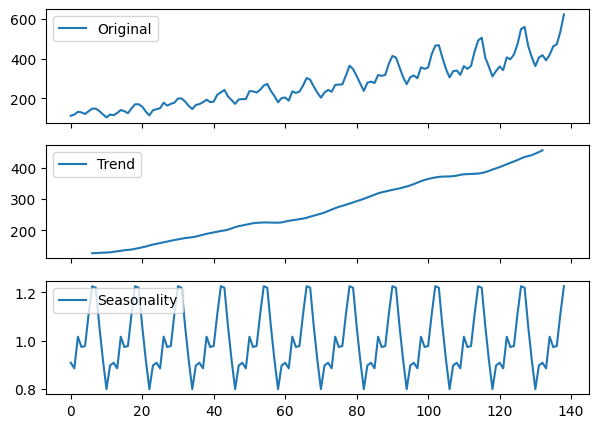

In [10]:
train_ts1_dec = seasonal_decompose(train_ts1, model='multiplicative', period=12)
seas_decomp_plots(train_ts1, train_ts1_dec)

Ряд train_ts1 относится к мультипликативной модели, у него присутствуют тренд и сезонность. Тренд линейный. Сезонность аддитивная.

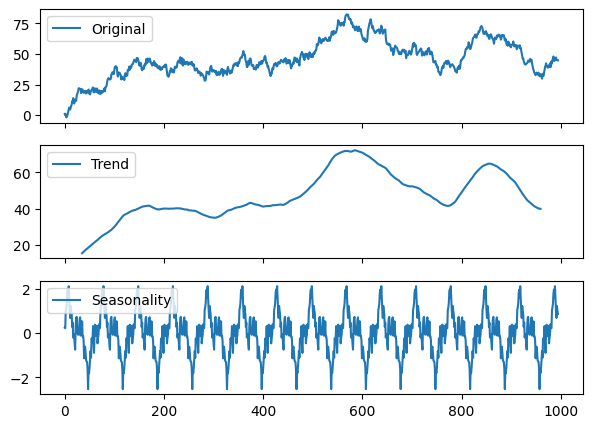

In [11]:
train_ts2_dec = seasonal_decompose(train_ts2, model='additive', period=70)
seas_decomp_plots(train_ts2, train_ts2_dec)

Ряд train_ts2 не относится ни к аддитивной модели, ни к мультипликативной, больше похож на случайное блуждание. У него не выражен тренд, хотя наблюдается аддитвная сезонность с постоянной амплитудой.

In [12]:
from statsmodels.tsa.api import ExponentialSmoothing

triple = ExponentialSmoothing(train_ts1,
                              trend="additive",
                              seasonal="additive",
                              seasonal_periods=12).fit(optimized=True)
triple_preds = triple.forecast(len(test_ts1))
triple_mse = mse(test_ts1, triple_preds)
print("Predictions: ", triple_preds)
print("MSE: ", triple_mse)

Predictions:  [608.38107418 508.41359897 452.03445266 406.23544751 445.47299758]
MSE:  106.26660746444864


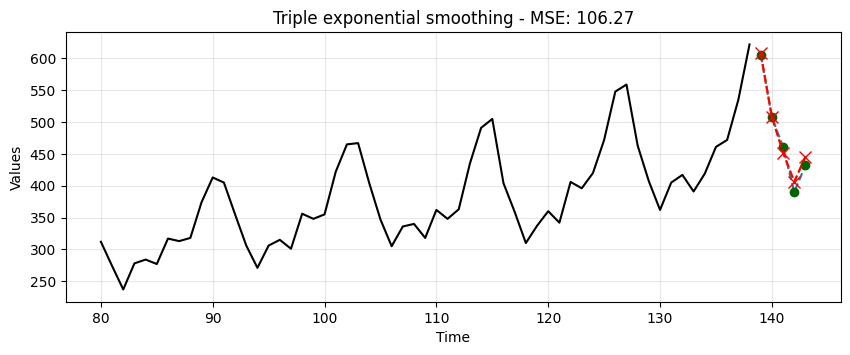

In [13]:
# mytime1 и train_ts1 ограничены для более наглядной визуализации
ax = run_sequence_plot(mytime1[80:-5], train_ts1[80:], title=f"Triple exponential smoothing - MSE: {triple_mse:.2f}")
ax.plot(mytime1[-5:], test_ts1, color='tab:blue', linestyle="--", label="test")
ax.plot(mytime1[-5:], triple_preds, color='tab:orange', linestyle="--", label="preds");

# тестовые данные (реальные)
plt.plot(mytime1[-5:], test_ts1, color='darkgreen', marker='o',
         linestyle='', markersize=6, label='Тестовые данные (реальные)')

# прогноз на тестовый период
plt.plot(mytime1[-5:], triple_preds, color='red', marker='x',
         linestyle='--', markersize=8, label='Прогноз модели')

Для ряда smoothing_ts1 сразу применяем тройное экспоненциальное сглаживание, т.к. у модели есть и тред, и сезонность. MSE показала наименьшое значение при параметрах trend="additive" и seasonal="additive", значит изначальные предположения были верны. Видно, что прогноз хорошо повторяет тестовые данные.

In [14]:
from statsmodels.tsa.api import ExponentialSmoothing

triple = ExponentialSmoothing(train_ts2,
                              trend="additive",
                              seasonal="additive",
                              seasonal_periods=12).fit(optimized=True)
triple_preds = triple.forecast(len(test_ts1))
triple_mse = mse(test_ts2, triple_preds)
print("Predictions: ", triple_preds)
print("MSE: ", triple_mse)

Predictions:  [44.65774637 44.72771264 44.41093046 44.50269492 44.6354472 ]
MSE:  2.9764812005627066


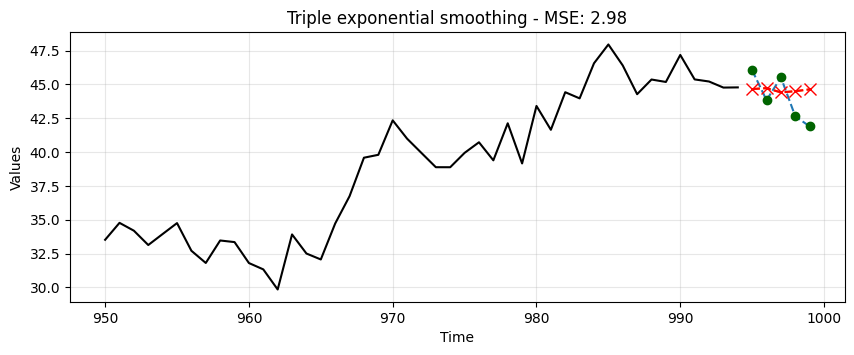

In [15]:
# mytime2 и train_ts2 ограничены для более наглядной визуализации
ax = run_sequence_plot(mytime2[950:-5], train_ts2[950:], title=f"Triple exponential smoothing - MSE: {triple_mse:.2f}")
ax.plot(mytime2[-5:], test_ts2, color='tab:blue', linestyle="--", label="test")
ax.plot(mytime2[-5:], triple_preds, color='tab:orange', linestyle="--", label="preds");

# Тестовые данные (реальные)
plt.plot(mytime2[-5:], test_ts2, color='darkgreen', marker='o',
         linestyle='', markersize=6, label='Тестовые данные (реальные)')

# Прогноз на тестовый период
plt.plot(mytime2[-5:], triple_preds, color='red', marker='x',
         linestyle='--', markersize=8, label='Прогноз модели')

Для ряда smoothing_ts2 применяем тройное экспоненциальное сглаживание, т.к. это наилучшее сглаживание из доступных. Однако, результат тестирования не очень хороший. Предсказания сильно сглаживают тестовые данные.